## Candidate Model Selection
I selected XGBoost as the baseline model for forecasting weekly *Karenia brevis* conditions in the Sarasota area. This notebook evaluates forecasts at one-, two-, and four-week horizons using the merged weekly dataset.

The experiment compares two model configurations: a baseline using all 85 eligible features and a feature-selected model using the 15 most important features identified within each training fold. Both configurations use the default `XGBClassifier()` settings.

I use forward-chaining evaluation organized by August–July bloom years. For each fold, the model is trained only on observations whose target dates precede the start of the test period. Performance is evaluated using accuracy and macro-F1. Random Forest and support vector machines remain possible comparison models for future experiments.

### Install XGBoost

In [44]:
# !pip install xgboost

### Import Libraries

In [45]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt

### Connect to Drive

In [46]:
from google.colab import drive
import os

drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/data'

if os.path.exists(DATA_DIR):
    print(f"Data directory '{DATA_DIR}' exists.")
    os.chdir(DATA_DIR)
else:
    print(f"Data directory '{DATA_DIR}' does not exist.")

print(os.getcwd())
print(os.listdir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data directory '/content/drive/MyDrive/data' exists.
/content/drive/.shortcut-targets-by-id/1_ib6SYLLQ6Asjybns0GSlgBDwFQrnmkj/data
['bradentonFL_tempData.csv', 'florida_cyanotoxins_2015-01-01_to_2026-06-17.csv', 'habsos_cellcounts.csv', 'cleaned', 'NutrientsFL_2006_2025.csv', 'MoteMarine_BottomTemp.csv', 'engineered', 'merged', 'ChlorophyllaConcentrationSarasota.txt', 'ChlorophyllaConcentrationSarasota_Dataset2.txt', 'SarasotaWindData.txt', 'Sarasota_Wind&Temp.csv', 'ChlorophyllaConcentrationSarasota_engineered.csv', 'chirps20GlobalDailyP05_0878_d358_0bc6.txt', 'chirps20GlobalDailyP05_0878_d358_0bc6_cleaned.csv', 'wind_daily.csv']


### Load the Weekly Dataset

Load `merged/merged_weekly_sarasota.csv` and inspect its columns. The dataset includes *K. brevis* measurements, environmental variables, lagged and rolling features, and targets for one-, two-, and four-week forecasts.

In [47]:
# Load the existing dataset
dataset = pd.read_csv("merged/merged_weekly_sarasota.csv")
dataset.columns

Index(['week_ending', 'kb_n_samples', 'kb_max', 'kb_max_log', 'kb_p95_log',
       'kb_mean_log', 'kb_frac_1e4', 'kb_frac_1e5', 'rkb_max_log',
       'rkb_frac_1e5', 'rkb_n_samples', 'kb_class', 'last_class',
       'weeks_since_sample', 'weeks_since_bloom', 'kb_max_log_L1',
       'kb_frac_1e5_L1', 'rkb_max_log_L1', 'kb_max_log_L2', 'kb_frac_1e5_L2',
       'rkb_max_log_L2', 'kb_max_log_4w', 'kb_max_log_8w', 'rkb_max_log_4w',
       'chl_p90', 'chl_frac_gt1', 'chl_frac_gt5', 'chl_coastal_mean',
       'chl_mean_log', 'chl_anomaly', 'chl_coastal_anomaly',
       'chl_mean_log_change_1w', 'bay_tn_8w', 'bay_tp_8w', 'bay_nox_8w',
       'bay_po4_8w', 'bay_chl_insitu_8w', 'bay_spcond_8w', 'bay_turbidity_8w',
       'bay_do_8w', 'creek_tn_8w', 'creek_tp_8w', 'creek_nox_8w', 'bay_bod_8w',
       'bay_ph_8w', 'bay_tkn_8w', 'bay_do_sat_8w', 'bay_tss_8w',
       'bay_color_8w', 'creek_po4_8w', 'creek_nh3_8w', 'creek_chl_insitu_8w',
       'creek_chl_uncorr_8w', 'creek_spcond_8w', 'creek_turbidi

### Prepare the Baseline Evaluation

Convert `week_ending` to a datetime value and sort observations chronologically. Exclude the date column and all three target columns from the model inputs. Initialize containers for model performance and feature-importance results across forecast horizons and test years.

In [48]:
# Convert dates and sort chronologically
dataset["week_ending"] = pd.to_datetime(dataset["week_ending"])
dataset = dataset.sort_values("week_ending").reset_index(drop=True)

# Columns that should not be used as model features
exclude = ["week_ending", "target_1w", "target_2w", "target_4w"]

# Store baseline metrics, feature-selected metrics, and feature importances
results = []
feature_importance_results = []

### Train and Evaluate XGBoost Models

Evaluate one-, two-, and four-week forecasts using forward-chaining folds labeled 2016–2026. Each test period runs from August 1 of the preceding year to August 1 of the labeled year, with the ending date excluded. Test observations are assigned by their forecast-origin dates.

For each horizon, remove observations with missing target values and calculate the corresponding target dates. Training observations are included only when their target dates fall before the test period begins. Folds with no training data, no test data, or fewer than two training classes are skipped.

Within each eligible fold:

1. Train a baseline XGBoost classifier using all eligible features.
2. Record its test accuracy, macro-F1, and feature importances.
3. Select the 15 highest-ranked features using only the fitted training-fold model.
4. Train a second classifier on those features and evaluate it on the same test observations.

Save the results for both configurations to compare performance across horizons and bloom years.

In [49]:
# Evaluate 1-, 2-, and 4-week prediction horizons
for horizon in [1, 2, 4]:

    target = f"target_{horizon}w"

    # Remove rows without a known target
    data = dataset.dropna(subset=[target]).copy()

    # Record when the forecast target occurs
    # This lets us exclude training labels that extend into the test period
    data["target_week"] = (
        data["week_ending"] + pd.to_timedelta(7 * horizon, unit="D")
    )

    # All eligible input features
    feature_cols = [col for col in dataset.columns if col not in exclude]

    # Do not use the target date as a model feature
    feature_cols = [
        col for col in feature_cols
        if col != "target_week"
    ]

    X = data[feature_cols]
    y = data[target]

    # Forward-chaining evaluation by August-July bloom year
    for year in range(2016, 2027):

        # Example: test year 2016 runs from August 2015 to July 2016
        test_start = pd.Timestamp(year=year - 1, month=8, day=1)
        test_end = pd.Timestamp(year=year, month=8, day=1)

        # Test on forecast-origin weeks within the test bloom year
        test_mask = (
            (data["week_ending"] >= test_start) &
            (data["week_ending"] < test_end)
        )

        # Train only on examples whose target date is before the test year
        train_mask = data["target_week"] < test_start

        X_train = X.loc[train_mask]
        y_train = y.loc[train_mask]

        X_test = X.loc[test_mask]
        y_test = y.loc[test_mask]

        # Skip folds without enough data or with only one training class
        if len(X_train) == 0 or len(X_test) == 0:
            continue

        if y_train.nunique() < 2:
            continue

        # ---------------------------------------------
        # MODEL 1: BASELINE XGBOOST
        # ---------------------------------------------

        # Keep the existing default XGBoost configuration
        baseline_model = XGBClassifier()

        # Train the baseline model using all eligible features
        baseline_model.fit(X_train, y_train)

        # Predict the test-year classes
        baseline_predictions = baseline_model.predict(X_test)

        # Calculate baseline performance
        baseline_accuracy = accuracy_score(
            y_test, baseline_predictions
        )

        baseline_macro_f1 = f1_score(
            y_test,
            baseline_predictions,
            average="macro",
            zero_division=0
        )

        # ---------------------------------------------
        # FEATURE IMPORTANCE
        # ---------------------------------------------

        # Save feature importance from the baseline training fold
        fold_importance = pd.DataFrame({
            "feature": X_train.columns,
            "importance": baseline_model.feature_importances_
        })

        fold_importance["horizon"] = horizon
        fold_importance["test_year"] = year

        feature_importance_results.extend(
            fold_importance.to_dict("records")
        )

        # Select the 15 most important features for this fold
        top_features = (
            fold_importance
            .nlargest(15, "importance")["feature"]
            .tolist()
        )

        # ---------------------------------------------
        # MODEL 2: FEATURE-SELECTED XGBOOST
        # ---------------------------------------------

        # Restrict training and test data to the selected features
        X_train_selected = X_train[top_features]
        X_test_selected = X_test[top_features]

        # Train a new XGBoost model using only the selected features
        selected_model = XGBClassifier()

        selected_model.fit(X_train_selected, y_train)

        # Predict using the feature-selected model
        selected_predictions = selected_model.predict(
            X_test_selected
        )

        # Calculate feature-selected model performance
        selected_accuracy = accuracy_score(
            y_test, selected_predictions
        )

        selected_macro_f1 = f1_score(
            y_test,
            selected_predictions,
            average="macro",
            zero_division=0
        )

        # Save results for both model versions
        results.append({
            "horizon": horizon,
            "test_year": year,
            "model": "Baseline XGBoost",
            "accuracy": baseline_accuracy,
            "macro_f1": baseline_macro_f1,
            "num_features": len(feature_cols)
        })

        results.append({
            "horizon": horizon,
            "test_year": year,
            "model": "Feature-Selected XGBoost",
            "accuracy": selected_accuracy,
            "macro_f1": selected_macro_f1,
            "num_features": len(top_features)
        })

        print(
            f"{horizon}-week | {year} | "
            f"Baseline accuracy: {baseline_accuracy:.3f} | "
            f"Selected accuracy: {selected_accuracy:.3f} | "
            f"Selected features: {len(top_features)}"
        )

1-week | 2016 | Baseline accuracy: 0.774 | Selected accuracy: 0.774 | Selected features: 15
1-week | 2017 | Baseline accuracy: 0.885 | Selected accuracy: 0.846 | Selected features: 15
1-week | 2018 | Baseline accuracy: 0.750 | Selected accuracy: 0.750 | Selected features: 15
1-week | 2019 | Baseline accuracy: 0.923 | Selected accuracy: 0.962 | Selected features: 15
1-week | 2020 | Baseline accuracy: 0.885 | Selected accuracy: 0.865 | Selected features: 15
1-week | 2021 | Baseline accuracy: 0.625 | Selected accuracy: 0.667 | Selected features: 15
1-week | 2022 | Baseline accuracy: 0.000 | Selected accuracy: 0.000 | Selected features: 15
1-week | 2023 | Baseline accuracy: 0.545 | Selected accuracy: 0.545 | Selected features: 15
1-week | 2024 | Baseline accuracy: 0.939 | Selected accuracy: 1.000 | Selected features: 15
1-week | 2025 | Baseline accuracy: 0.846 | Selected accuracy: 0.808 | Selected features: 15
1-week | 2026 | Baseline accuracy: 1.000 | Selected accuracy: 1.000 | Selected f

### Summarize and Visualize Evaluation Results

Display accuracy, macro-F1, and feature counts for each model, forecast horizon, and test year. Then calculate the arithmetic mean of each metric across the available test years for each configuration. These summaries give each included test year equal weight rather than pooling predictions across years.

Plot annual accuracy and macro-F1 to compare the baseline and feature-selected models and show how their performance varies across test periods.

In [50]:
# Convert saved results into a DataFrame
results_df = pd.DataFrame(results)

# Display metrics for each horizon, year, and model
display(
    results_df.sort_values(
        ["horizon", "test_year", "model"]
    ).reset_index(drop=True)
)

# Summarize average performance across test years
summary_df = (
    results_df
    .groupby(["horizon", "model"])[
        ["accuracy", "macro_f1", "num_features"]
    ]
    .mean()
    .reset_index()
)

print("Average performance across available test years:")
display(summary_df)

,horizon,test_year,model,accuracy,macro_f1,num_features
0,1,2016,Baseline XGBoost,0.773585,0.583639,85
1,1,2016,Feature-Selected XGBoost,0.773585,0.585673,15
2,1,2017,Baseline XGBoost,0.884615,0.706815,85
3,1,2017,Feature-Selected XGBoost,0.846154,0.679047,15
4,1,2018,Baseline XGBoost,0.750000,0.595623,85
...,...,...,...,...,...,...
61,4,2024,Feature-Selected XGBoost,0.944444,0.485714,15
62,4,2025,Baseline XGBoost,0.807692,0.654684,85
63,4,2025,Feature-Selected XGBoost,0.788462,0.659341,15
64,4,2026,Baseline XGBoost,1.000000,1.000000,85


Average performance across available test years:


,horizon,model,accuracy,macro_f1,num_features
0,1,Baseline XGBoost,0.742900,0.559070,85.0
1,1,Feature-Selected XGBoost,0.746952,0.618751,15.0
2,2,Baseline XGBoost,0.747599,0.550765,85.0
3,2,Feature-Selected XGBoost,0.668588,0.457556,15.0
4,4,Baseline XGBoost,0.708317,0.516881,85.0
5,4,Feature-Selected XGBoost,0.699713,0.495870,15.0


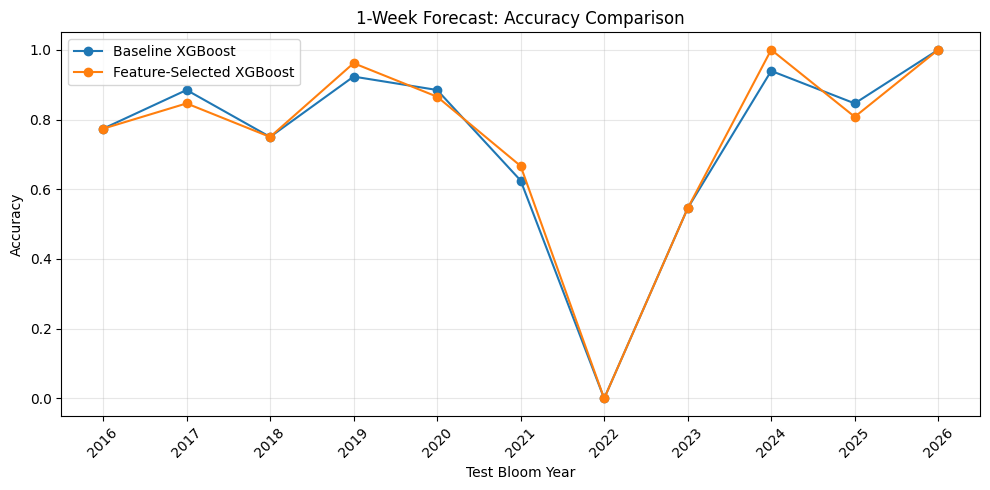

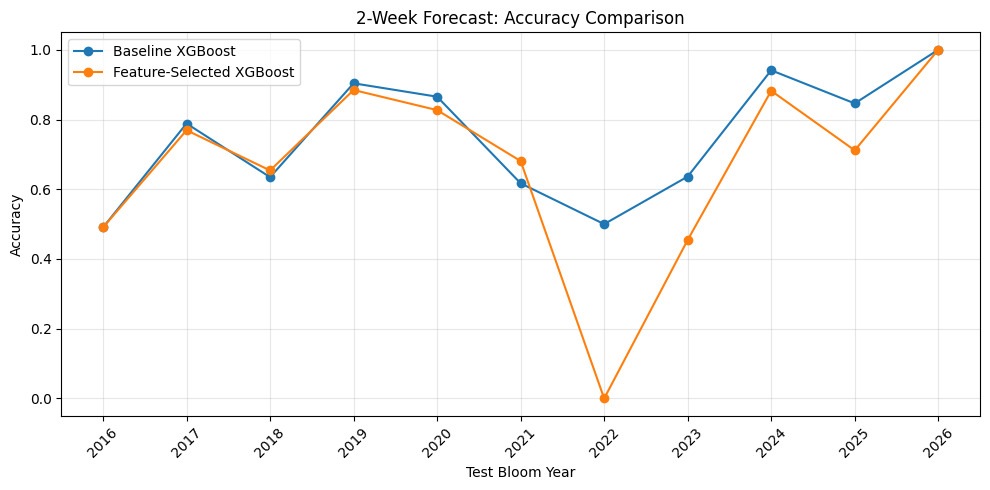

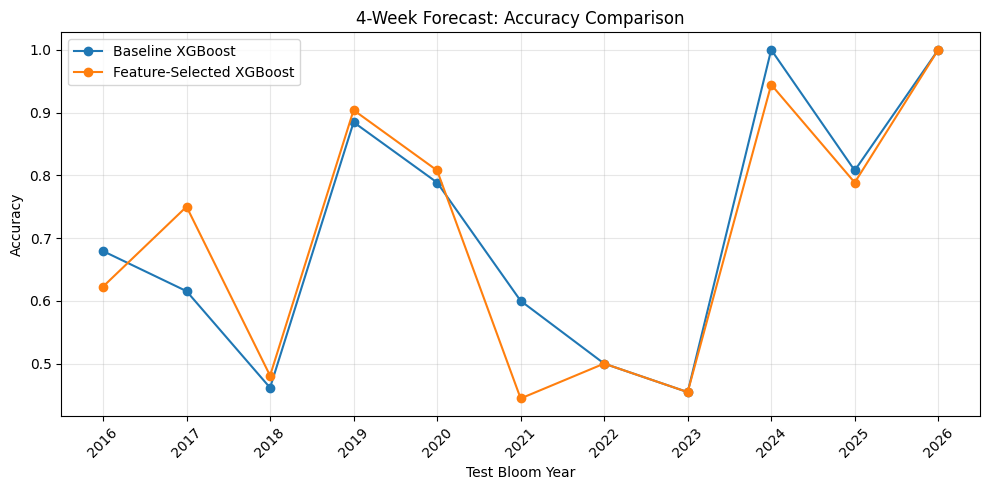

In [51]:
# Plot test-year accuracy for each prediction horizon
for horizon in [1, 2, 4]:

    horizon_results = results_df[
        results_df["horizon"] == horizon
    ]

    plt.figure(figsize=(10, 5))

    for model_name in horizon_results["model"].unique():

        model_results = horizon_results[
            horizon_results["model"] == model_name
        ].sort_values("test_year")

        plt.plot(
            model_results["test_year"],
            model_results["accuracy"],
            marker="o",
            label=model_name
        )

    plt.xlabel("Test Bloom Year")
    plt.ylabel("Accuracy")
    plt.title(f"{horizon}-Week Forecast: Accuracy Comparison")
    plt.xticks(range(2016, 2027), rotation=45)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

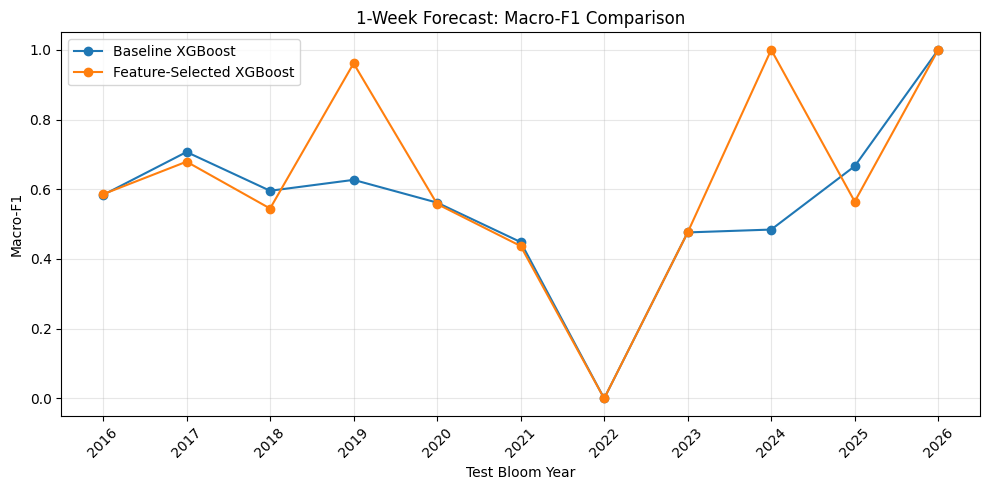

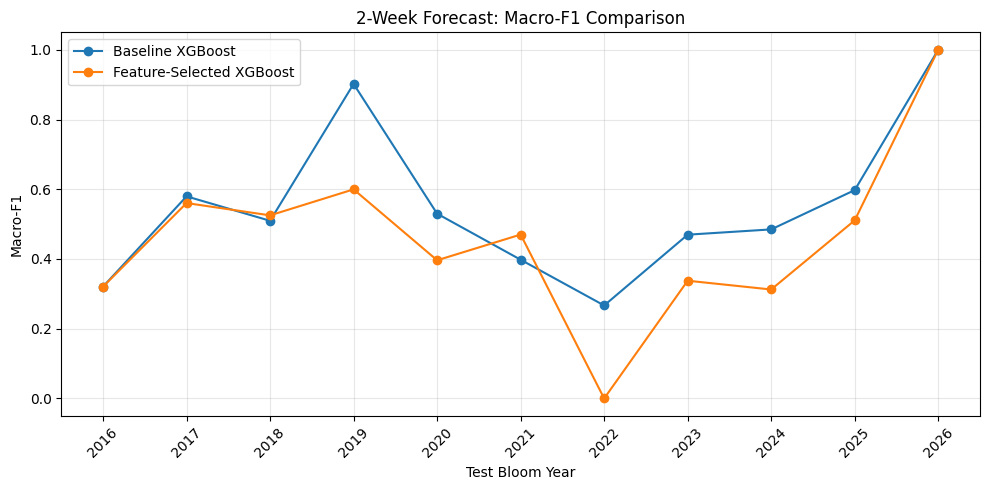

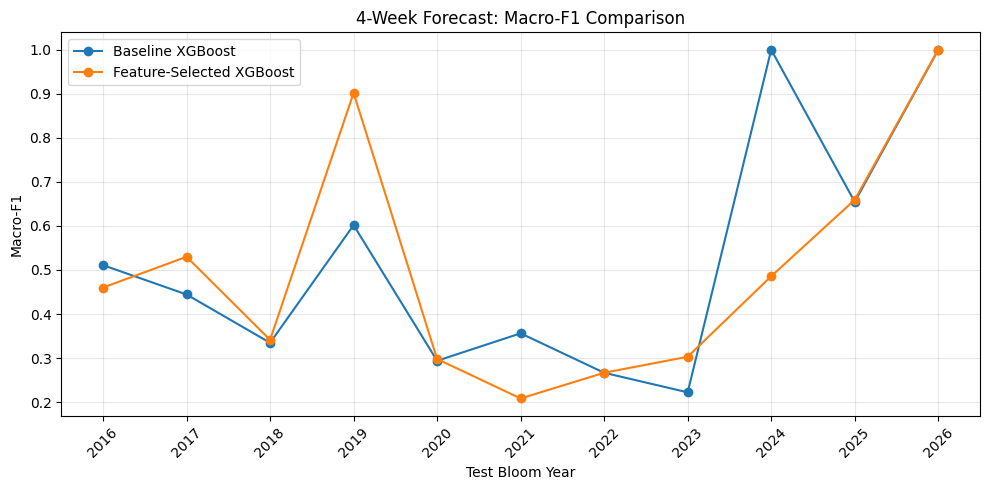

In [52]:
# Plot test-year macro-F1 for each prediction horizon
for horizon in [1, 2, 4]:

    horizon_results = results_df[
        results_df["horizon"] == horizon
    ]

    plt.figure(figsize=(10, 5))

    for model_name in horizon_results["model"].unique():

        model_results = horizon_results[
            horizon_results["model"] == model_name
        ].sort_values("test_year")

        plt.plot(
            model_results["test_year"],
            model_results["macro_f1"],
            marker="o",
            label=model_name
        )

    plt.xlabel("Test Bloom Year")
    plt.ylabel("Macro-F1")
    plt.title(f"{horizon}-Week Forecast: Macro-F1 Comparison")
    plt.xticks(range(2016, 2027), rotation=45)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Model Performance Summary

The saved evaluation results show the following mean performance across the available test years:

| Forecast horizon | Baseline accuracy | Baseline macro-F1 | Top-15 accuracy | Top-15 macro-F1 |
| --- | --- | --- | --- | --- |
| 1 week | 74.29% | 0.5591 | 74.70% | 0.6188 |
| 2 weeks | 74.76% | 0.5508 | 66.86% | 0.4576 |
| 4 weeks | 70.83% | 0.5169 | 69.97% | 0.4959 |

The feature-selected one-week model achieved the highest mean macro-F1 and slightly higher mean accuracy than its baseline counterpart. At the two- and four-week horizons, the baseline outperformed the feature-selected model on both metrics.

The two-week baseline achieved the highest mean accuracy overall, while the feature-selected one-week model achieved the highest mean macro-F1.

Performance varied across test years, so these averages should be interpreted alongside the annual plots. The current evaluation reports accuracy and macro-F1; it does not calculate AUC, weighted F1, or separate precision and recall results.

### Examine Feature Importance

Average the baseline models' feature-importance scores across test years separately for each forecast horizon. Display and plot the 15 highest-ranked features for each horizon.

These aggregate rankings summarize the fitted baseline models. The feature-selected models evaluated above use rankings calculated separately within each training fold.

Top features for the 1-week forecast:


,horizon,feature,importance
56,1,kb_mean_log,0.173628
50,1,kb_max,0.122166
58,1,kb_p95_log,0.095852
46,1,kb_frac_1e4,0.046512
10,1,bay_spcond_8w,0.029054
9,1,bay_po4_8w,0.028920
47,1,kb_frac_1e5,0.022448
68,1,rkb_max_log,0.021775
60,1,last_class,0.019655
26,1,creek_chl_uncorr_8w,0.017234


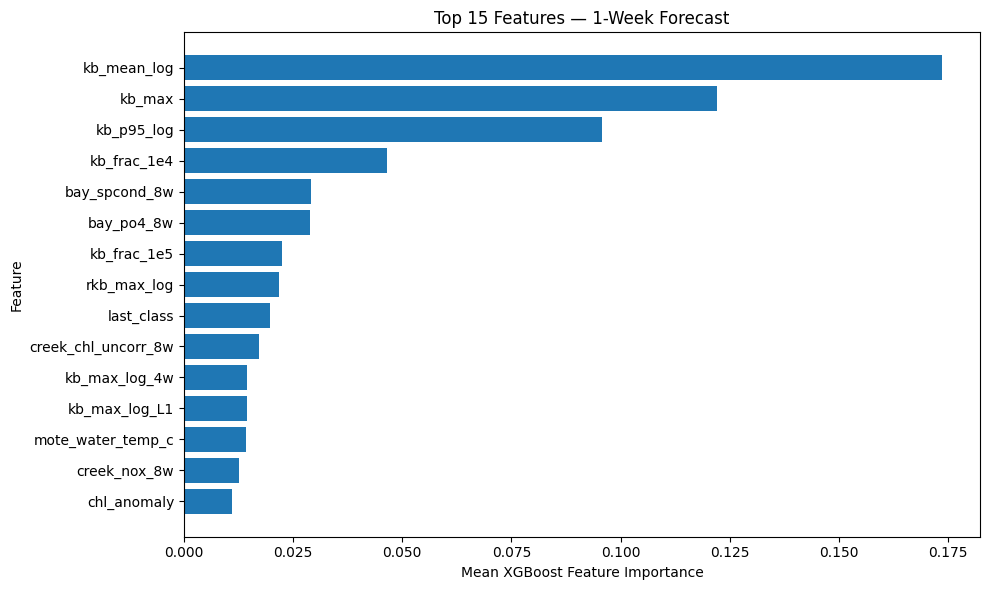

Top features for the 2-week forecast:


,horizon,feature,importance
135,2,kb_max,0.210951
131,2,kb_frac_1e4,0.131797
141,2,kb_mean_log,0.100061
145,2,last_class,0.078309
94,2,bay_po4_8w,0.029261
111,2,creek_chl_uncorr_8w,0.021953
139,2,kb_max_log_L1,0.017340
97,2,bay_tn_8w,0.014268
161,2,weeks_since_bloom,0.011948
119,2,creek_po4_8w,0.011419


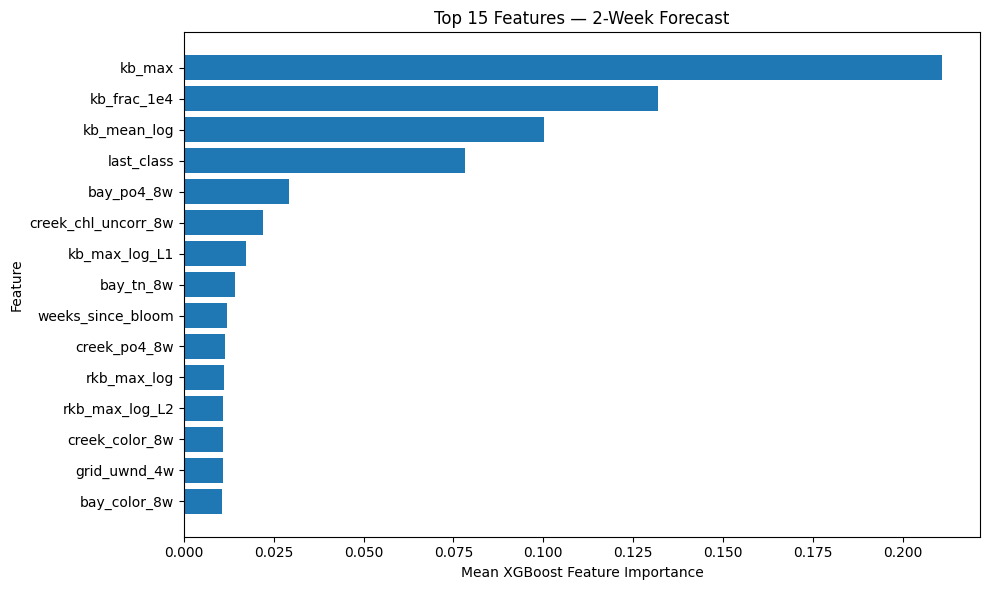

Top features for the 4-week forecast:


,horizon,feature,importance
220,4,kb_max,0.186416
226,4,kb_mean_log,0.063343
197,4,creek_color_8w,0.060929
185,4,bay_turbidity_8w,0.044421
222,4,kb_max_log_4w,0.039637
179,4,bay_po4_8w,0.032260
228,4,kb_p95_log,0.023688
196,4,creek_chl_uncorr_8w,0.023128
170,4,air_temp_f,0.022883
204,4,creek_po4_8w,0.021303


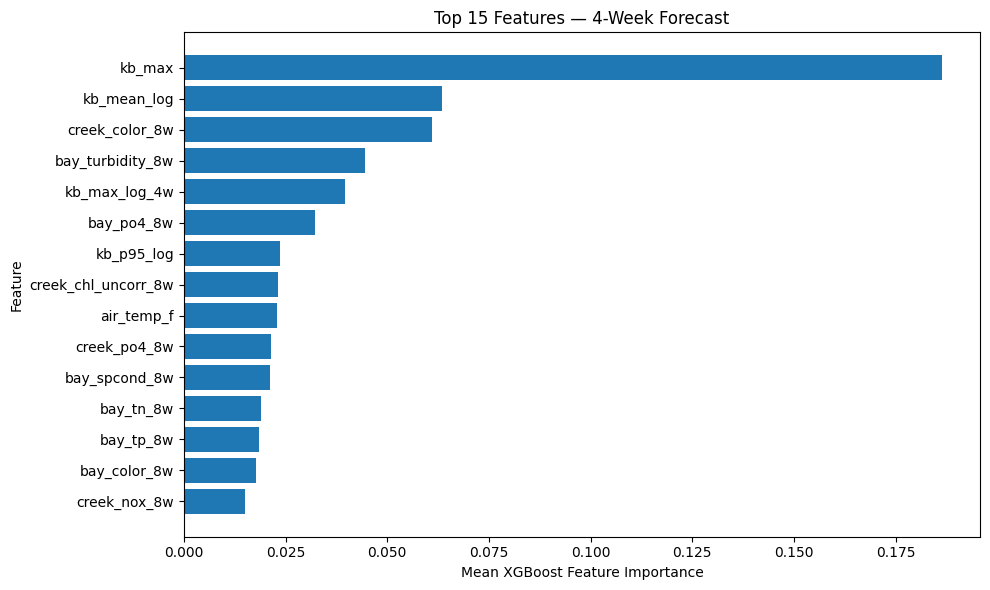

In [53]:
# Convert saved feature importances into a DataFrame
feature_importance_df = pd.DataFrame(
    feature_importance_results
)

# Average importance across test years for each horizon
feature_importance_summary = (
    feature_importance_df
    .groupby(["horizon", "feature"])["importance"]
    .mean()
    .reset_index()
)

# Display the top 15 features for each prediction horizon
for horizon in [1, 2, 4]:

    top_features = (
        feature_importance_summary[
            feature_importance_summary["horizon"] == horizon
        ]
        .nlargest(15, "importance")
        .sort_values("importance")
    )

    print(f"Top features for the {horizon}-week forecast:")
    display(top_features.sort_values("importance", ascending=False))

    # Plot feature importance
    plt.figure(figsize=(10, 6))

    plt.barh(
        top_features["feature"],
        top_features["importance"]
    )

    plt.xlabel("Mean XGBoost Feature Importance")
    plt.ylabel("Feature")
    plt.title(f"Top 15 Features — {horizon}-Week Forecast")
    plt.tight_layout()
    plt.show()

## Conclusion

The feature selection experiment compared the baseline model using all 85 eligible features with a model using the 15 most important features from each training fold. The feature-selected model improved one-week accuracy from 74.29% to 74.70% and macro-F1 from 0.5591 to 0.6188. However, it achieved lower accuracy and macro-F1 than the baseline at the two- and four-week prediction horizons.

The feature-importance results ranked `kb_mean_log` highest for the one-week forecast and `kb_max` highest for the two- and four-week forecasts. These results show that the fitted models relied heavily on K. brevis measurements, although feature importance does not establish a causal relationship.

These findings suggest that a smaller set of features may improve short-term predictions but does not consistently improve performance across all prediction horizons. Further experiments are necessary to determine whether other feature subsets or model configurations provide more reliable performance on unseen data.

## Resources
1. https://machinelearningmastery.com/develop-first-xgboost-model-python-scikit-learn/